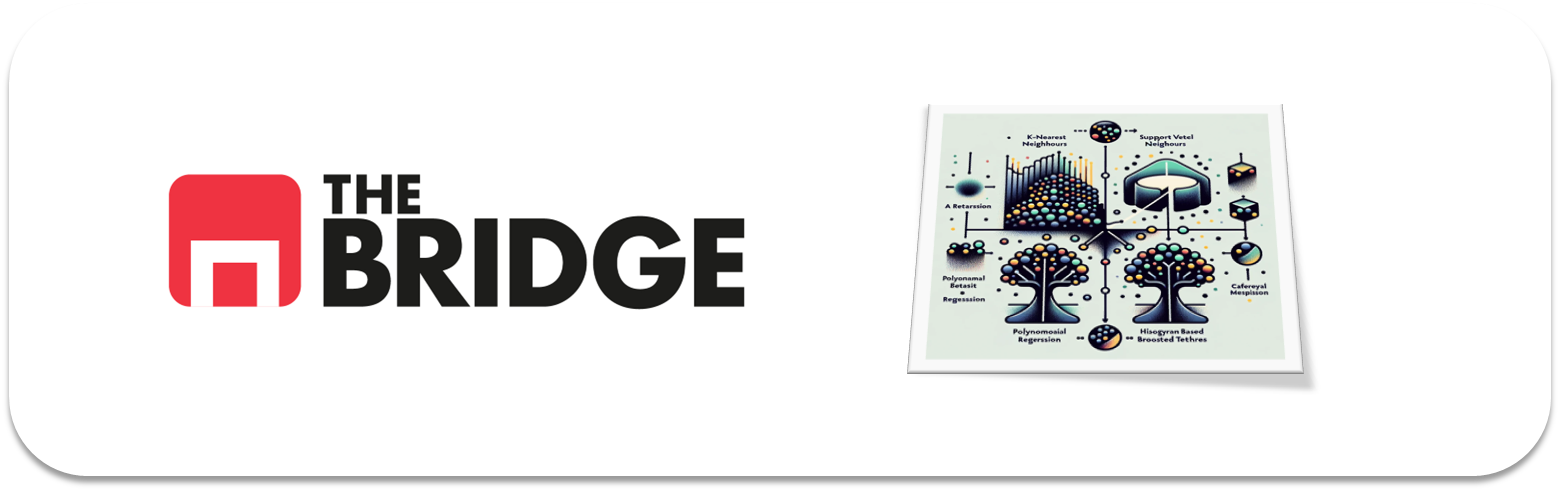

# Otros Modelos: k-Nearest Neighbours (KNN)

El KNN se basa en una idea muy intuitiva: "dime con quién andas y te diré quién eres". Para predecir algo sobre un elemento nuevo, buscamos los K elementos del train más parecidos a él (sus vecinos más cercanos) y nos fijamos en lo que les pasa a ellos.

Lo vamos a ver primero con un ejemplo de juguete, con solo dos features para poder pintarlo, y después veremos cómo afecta la elección de K y cómo se usa para regresión.

### Un ejemplo pequeño

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

Tenemos una encuesta antigua a 10 alumnos en la que se recogía su altura, su peso y qué saga de películas preferían: Harry Potter o Los Juegos del Hambre (Katniss Everdeen). Queremos predecir la preferencia de 10 alumnos nuevos de los que solo conocemos la altura y el peso.

Ojo: es un ejemplo de juguete. No esperamos que la altura y el peso expliquen los gustos de cine; lo usamos porque, con solo dos features, podemos pintar los datos y ver qué hace el algoritmo.

Este es el dataset de entrenamiento:

In [2]:

alumnos_train = {'Roberto': [1.63, 81, 0],
 'Lucia': [1.5, 74, 1],
 'Alejandro': [1.5, 54, 0],
 'Valeria': [1.93, 64, 1],
 'Javier': [1.5, 66, 0],
 'Camila': [1.71, 71, 1],
 'Diego': [1.95, 45, 1],
 'Gabriela': [1.54, 49, 0],
 'Mateo': [1.86, 50, 1],
 'Sofía': [1.77, 70, 0]
 }


Y este el de test, del que tenemos que predecir la preferencia:

In [3]:
nuevos_alumnos = {
 'William': [1.52, 72],
 'Emily': [1.52, 52],
 'Alexander': [1.93, 65],
 'Olivia': [1.51, 68],
 'Benjamin': [1.73, 69],
 'Sophia': [1.96, 40],
 'Henry': [1.55, 51],
 'Isabella': [1.87, 53],
 'James': [1.77, 70],
 'Charlotte': [1.65, 84]
}

Cada vector contiene la altura (en metros), el peso (en kg) y, solo en el train, la preferencia: 0 para Harry Potter y 1 para Katniss. De los alumnos nuevos no la sabemos: es lo que hay que predecir.

### Cómo funciona el KNN

El K-NN (K-Nearest Neighbours) para clasificación es un algoritmo muy sencillo: dado un dataset de entrada, si quiero predecir una variable para un nuevo elemento o instancia, se procede así:

1- Obtengo los K elementos del dataset de train que están más cerca del nuevo elemento. La cercanía se mide con una distancia entre los vectores de features (por defecto, la euclídea de toda la vida). Utilizo todas las variables o dimensiones del vector disponibles menos la que quiero calcular. 

2- Si la variable es categórica, se obtiene el hard-voting de los vecinos, es decir, se asigna la moda para dicha variable de los vecinos escogidos en el paso anterior.

3- Si la variable es numérica, se obtiene la media para los vecinos y esa media es el valor que se "predice" o asigna (en `sklearn` es el `KNeighborsRegressor`, que se usa igual que el clasificador).

Así de sencillo... No, no vamos a programarlo, dejaremos que `sklearn` haga el trabajo por nosotros. Pero antes veámoslo a ojo con nuestros datos.

**Los datos en un gráfico**

El siguiente diagrama muestra los alumnos del train y dos de los nuevos, William y Sophia, para los que hay que predecir la preferencia:

In [4]:


def pinta_alumnos(diccionario_vectores, etiquetas_leyendas = ["Harry","Katniss"], etiquetas_colores = ["black","red"]):
    # Separar los componentes de los vectores y las claves
    fig, axs = plt.subplots(figsize = (7,7))
    xs = {}
    ys = {}
    colores = {}
    etiquetas = {}
    for etiqueta in etiquetas_leyendas:
        xs[etiqueta] =[]
        ys[etiqueta] = []
        colores[etiqueta] = []
        etiquetas[etiqueta] = []

    for clave, vector in diccionario_vectores.items():
        xs[etiquetas_leyendas[vector[2]]].append(vector[0])
        ys[etiquetas_leyendas[vector[2]]].append(vector[1])
        colores[etiquetas_leyendas[vector[2]]].append(etiquetas_colores[vector[2]])
        etiquetas[etiquetas_leyendas[vector[2]]].append(clave)

    # Crear el scatter plot
    for etiqueta in etiquetas_leyendas:
        if etiqueta in xs:
            axs.scatter(xs[etiqueta], ys[etiqueta], c=colores[etiqueta], label = etiqueta)
            for i, nombre in enumerate(etiquetas[etiqueta]):
                axs.annotate(nombre, (xs[etiqueta][i], ys[etiqueta][i]))
    
    # Anotar cada punto con su clave
    

    # Configurar el gráfico
    axs.grid(False) # Desactivar la rejilla
    axs.set_xlabel("Altura")
    axs.set_ylabel("Peso")
    axs.legend()
    return axs

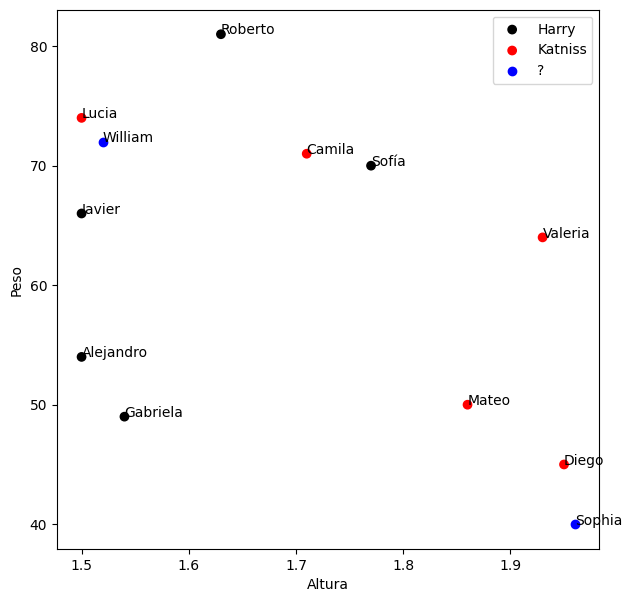

In [5]:
fig = pinta_alumnos(alumnos_train)
vec_will = nuevos_alumnos["William"]
vec_soph = nuevos_alumnos["Sophia"]
fig.scatter([vec_will[0],vec_soph[0]],[vec_will[1], vec_soph[1]], color = "blue", label = "?")
plt.annotate("William",(vec_will))
plt.annotate("Sophia", (vec_soph))
fig.legend()

Suponiendo K = 3 (y mirando el gráfico, en el que, ojo, cada eje tiene su propia escala):

- La predicción de William saldrá de considerar a Lucia, Roberto y Javier
- La predicción de Sophia saldrá de considerar a Diego, Mateo, Valeria

### Implementación

Veamos cómo se implementa:

In [6]:
# Convertimos los diccionarios en X,y

train_set = pd.DataFrame([(clave,vec[0],vec[1],vec[2]) for clave,vec in alumnos_train.items()], columns = ["alumno","altura","peso","preferencia"])
train_set.set_index("alumno", inplace = True)
train_set

,altura,peso,preferencia
alumno,,,
Roberto,1.63,81,0
Lucia,1.50,74,1
Alejandro,1.50,54,0
Valeria,1.93,64,1
Javier,1.50,66,0
Camila,1.71,71,1
Diego,1.95,45,1
Gabriela,1.54,49,0
Mateo,1.86,50,1


In [7]:
test_set = pd.DataFrame([(clave,vec[0],vec[1]) for clave,vec in nuevos_alumnos.items()], columns = ["alumno","altura","peso"])
test_set.set_index("alumno",inplace = True)
test_set

,altura,peso
alumno,,
William,1.52,72
Emily,1.52,52
Alexander,1.93,65
Olivia,1.51,68
Benjamin,1.73,69
Sophia,1.96,40
Henry,1.55,51
Isabella,1.87,53
James,1.77,70


In [8]:

knn = KNeighborsClassifier(n_neighbors=3)

X = train_set[['altura','peso']].copy()
y = train_set['preferencia']

knn.fit(X,y)

prediccion = knn.predict(test_set)
test_set["Prediccion"] = np.where(prediccion == 0, "Harry","Katniss")
test_set

,altura,peso,Prediccion
alumno,,,
William,1.52,72,Katniss
Emily,1.52,52,Harry
Alexander,1.93,65,Harry
Olivia,1.51,68,Harry
Benjamin,1.73,69,Harry
Sophia,1.96,40,Katniss
Henry,1.55,51,Harry
Isabella,1.87,53,Harry
James,1.77,70,Katniss


Hmmm pero esto no es lo que esperábamos... es sensible a la escala

### Sensible a la escala

Tenemos que escalar:

In [9]:
scaler = StandardScaler()
X[["altura","peso"]] = scaler.fit_transform(X[["altura","peso"]])
test_set[["altura","peso"]] = scaler.transform(test_set[["altura","peso"]])

In [10]:

knn.fit(X,y)

prediccion = knn.predict(test_set[["altura","peso"]])
test_set["Prediccion"] = np.where(prediccion == 0, "Harry","Katniss")
test_set

,altura,peso,Prediccion
alumno,,,
William,-0.983473,0.831052,Harry
Emily,-0.983473,-0.900306,Harry
Alexander,1.402467,0.225077,Katniss
Olivia,-1.041666,0.484780,Katniss
Benjamin,0.238594,0.571348,Harry
Sophia,1.577048,-1.939121,Katniss
Henry,-0.808892,-0.986874,Harry
Isabella,1.053305,-0.813738,Katniss
James,0.471369,0.657916,Katniss


### Selección de la K

- La mejor elección de K depende de los datos: no hay una fórmula que nos dé el valor óptimo.
- Lo habitual es probar varios valores de K y quedarse con el que mejor resultado da en validación cruzada (lo harás en los ejercicios).
- Valores pequeños de K dan fronteras de decisión muy irregulares, que se ajustan al ruido (overfitting).
- Valores grandes de K suavizan la frontera, pero si nos pasamos el modelo se vuelve demasiado simple (underfitting).

Veámoslo con un dataset sintético de dos "lunas" entrelazadas (sus dos features ya están en rangos parecidos, así que aquí no hace falta escalar):

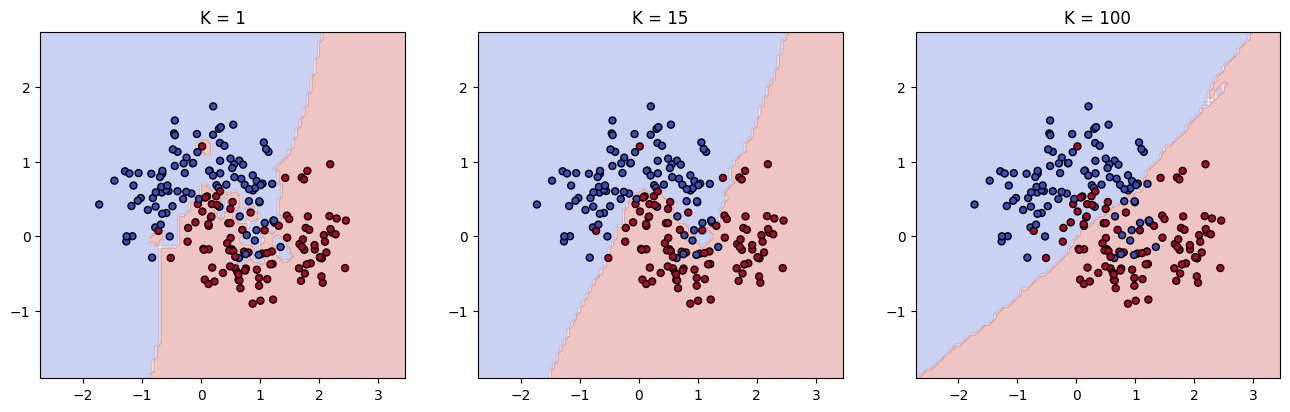

In [11]:
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay

X_lunas, y_lunas = make_moons(n_samples=200, noise=0.3, random_state=42)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axs, [1, 15, 100]):
    knn_k = KNeighborsClassifier(n_neighbors=k).fit(X_lunas, y_lunas)
    DecisionBoundaryDisplay.from_estimator(knn_k, X_lunas, response_method="predict", cmap="coolwarm", alpha=0.3, ax=ax)
    ax.scatter(X_lunas[:, 0], X_lunas[:, 1], c=y_lunas, cmap="coolwarm", edgecolors="k", s=25)
    ax.set_title(f"K = {k}")
plt.show()

- Con **K = 1** la frontera es muy irregular: hace "islas" alrededor de puntos sueltos de la otra clase. Se aprende el ruido (overfitting).
- Con **K = 15** la frontera es suave y sigue bien la forma de las dos lunas.
- Con **K = 100** (la mitad del dataset) la frontera es casi una recta: ya no capta la curvatura de las lunas (underfitting).

### KNN para regresión

Si el target es numérico, el KNN predice la media del target de los K vecinos. En `sklearn` se usa el `KNeighborsRegressor`, que funciona exactamente igual que el clasificador:

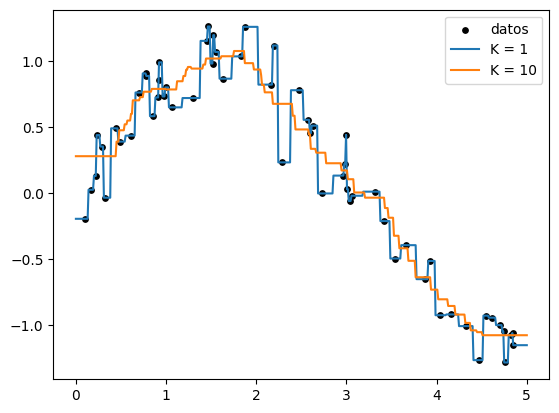

In [12]:
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.RandomState(42)
x_reg = np.sort(rng.uniform(0, 5, 60)).reshape(-1, 1)
y_reg = np.sin(x_reg).ravel() + rng.normal(0, 0.2, 60)
x_plot = np.linspace(0, 5, 500).reshape(-1, 1)

plt.scatter(x_reg, y_reg, color="black", s=15, label="datos")
for k in [1, 10]:
    knn_reg = KNeighborsRegressor(n_neighbors=k).fit(x_reg, y_reg)
    plt.plot(x_plot, knn_reg.predict(x_plot), label=f"K = {k}")
plt.legend()
plt.show()

La predicción es "a escalones": cada tramo es la media de los K vecinos de esa zona. Con K = 1 la curva pasa por todos los puntos y copia el ruido; con K = 10 es mucho más suave y se parece más a la tendencia real (una senoide). Es la misma idea que en clasificación.

### Para terminar

- El KNN no "aprende" nada al entrenar: simplemente guarda el train. Todo el trabajo se hace al predecir, calculando distancias a todos los puntos, así que con datasets grandes la predicción es lenta.
- Es sensible a la escala (siempre hay que escalar) y empeora cuando hay muchas features, porque en espacios con muchas dimensiones todos los puntos acaban estando "lejos" de todos.
- Sus hiperparámetros principales son `n_neighbors` (la K) y `weights` (`"uniform"`: todos los vecinos votan igual; `"distance"`: los más cercanos pesan más).

Documentación: https://scikit-learn.org/stable/modules/neighbors.html